# Fine-resolution grids over part of the domain

This notebook demonstrates the `fine_grid_args` option of `smooth_fit`, which adds fine-resolution grids that cover only a region of the fit domain.  We use it when a few small areas need more resolution than the rest of the domain, for example rifts on an ice shelf: a fine grid over the whole domain would multiply the size of the problem, while the coarse grids alone cannot resolve the rifts.  See the README for setup instructions, and `smooth_fit_demo.ipynb` for an introduction to the coarse fit.

## The model

Outside the region $R$, the model is the usual coarse model, $z_m = z_0 + \delta z$.  Inside $R$, we add a fine-resolution DEM, $z_{0,f}$, and a fine-resolution height-change field, $\delta z_f$:

$$
z_m(x, y, t) = z_0(x, y) + \delta z(x, y, t) + z_{0,f}(x, y) + \delta z_f(x, y, t),
\qquad \delta z_f(x, y, t_{ref}) = 0 .
$$

Here $t_{ref}$ is the time of the reference epoch, at which the coarse $\delta z$ is also zero.  The fine grids have model parameters only at nodes inside $R$, and only data near $R$ involve them.

The fine fields have their own smoothness constraints, usually much weaker than those on the coarse fields.  For example, the curvature constraint on $z_{0,f}$ adds

$$
R_{0,f} = \int_R \frac{\left(\partial_{xx} z_{0,f}\right)^2 + 2\left(\partial_{xy} z_{0,f}\right)^2 + \left(\partial_{yy} z_{0,f}\right)^2}{E_{xx,f}^2}\, dA
$$

to the misfit, alongside $(r/\sigma)^2$ for each datum, where $E_{xx,f}$ is `fine_grid_args['E_RMS']['d2z0_dx2']`.  A small $E_{xx,f}$ makes $z_{0,f}$ stiff; a large one lets it follow the data.  The finite-difference equations are centered on the nodes inside $R$, and nodes outside $R$ enter them as zero.  The constraints therefore pull the fine fields towards zero at the edge of $R$, so features larger than the region go into the coarse fields, and the fine fields resolve what the coarse fields cannot.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import shapely
import pointCollection as pc
from LSsurf.smooth_fit import smooth_fit
from LSsurf.lin_op import lin_op

# plot styling: text in ink, coarse fit in blue, coarse+fine fit in orange, diverging maps blue-gray-red
ink, ink2 = '#0b0b0b', '#52514e'
c_coarse, c_fine = '#2a78d6', '#eb6834'
div_cmap = LinearSegmentedColormap.from_list('div', ['#104281', '#3987e5', '#9ec5f4', '#f0efec',
                                                     '#f2a9a8', '#e34948', '#9c2a2a'])
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': ink2, 'axes.labelcolor': ink2, 'xtick.color': ink2, 'ytick.color': ink2})

## A synthetic rift

We work in an 8 km × 8 km domain over four years, in a Lagrangian frame, so the rift does not move with the ice.  The true surface is a smooth background that thins at about 0.5 m/yr, plus a rift: a trough along a curved line that deepens, widens, and propagates east,

$$
r(x, y, t) = -D(t) \exp\left(-\frac{d^2}{2\,w(t)^2}\right) s(x, t),
\qquad D(t) = 4\,(4 + 2t)\ \text{m}, \qquad w(t) = 60 + 20t\ \text{m}.
$$

Here $d$ is the distance from the rift's center line, and $s(x, t)$ is a taper that is 1 between $x = -2.4$ km and the rift tip at $x = 0.4 + 0.5t$ km, and 0 beyond them.  The trough is 16 m deep at t = 0 and 48 m deep at t = 4 yr.  A trough this narrow ($w$ = 60 to 140 m) cannot be represented on the coarse grids, which have 200 m nodes for $z_0$ and 1 km nodes for $\delta z$.

The data are near-north-south altimetry tracks (six per quarter, 20 m along-track, $\sigma$ = 0.1 m) and four DEM strips (40 m posting, $\sigma$ = 0.5 m).  Between DEM epochs, only the tracks sample the rift.

In [2]:
rng = np.random.default_rng(42)
HW = 4000.                 # half-width of the domain, m
t_ref = 2.                 # time of the reference epoch, yr

def rift_y(x):
    # y coordinate of the rift's center line
    return -500 + 800*np.sin(2*np.pi*x/12000)

def rift(x, y, t):
    slope = 800*2*np.pi/12000*np.cos(2*np.pi*x/12000)
    d = (y - rift_y(x))/np.sqrt(1+slope**2)
    x_tip = 400 + 500*t
    taper = 0.25*(1+np.tanh((x+2400)/150))*(1-np.tanh((x-x_tip)/150))
    return -4*(4+2*t)*np.exp(-0.5*(d/(60+20*t))**2)*taper

def z_true(x, y, t):
    z_bg = 50 + 2e-3*x - 1e-3*y + 3*np.cos(2*np.pi*x/6000)*np.cos(2*np.pi*y/7000)
    dz_bg = -0.5*t*(1 + 0.5*np.sin(2*np.pi*(x+y)/9000))
    return z_bg + dz_bg + rift(x, y, t)

# altimetry: six near-N-S tracks per quarter
D = []
for k in range(16):
    for track in range(6):
        t = 0.125 + 0.25*k + rng.uniform(-0.1, 0.1)
        y = np.arange(-HW, HW, 20.)
        x = rng.uniform(-HW, HW) + 0.05*y
        D.append(pc.data().from_dict({'x': x, 'y': y, 'time': np.zeros_like(x)+t,
                                      'sigma': np.zeros_like(x)+0.1, 'sensor': np.zeros_like(x)}))
# DEM strips, 5 km wide
DEM_times, DEM_xc = [0.3, 1.6, 2.9, 3.8], [-1000, 1200, 0, 800]
for t, xc in zip(DEM_times, DEM_xc):
    xg, yg = [jj.ravel() for jj in np.meshgrid(np.arange(xc-2500, xc+2500, 40.), np.arange(-HW, HW, 40.))]
    xg, yg = xg + rng.uniform(-20, 20, xg.size), yg + rng.uniform(-20, 20, yg.size)
    D.append(pc.data().from_dict({'x': xg, 'y': yg, 'time': np.zeros_like(xg)+t,
                                  'sigma': np.zeros_like(xg)+0.5, 'sensor': np.ones_like(xg)}))
data = pc.data().from_list(D)
data.index((np.abs(data.x) < HW-1) & (np.abs(data.y) < HW-1))
data.assign(z=z_true(data.x, data.y, data.time) + rng.normal(size=data.size)*data.sigma)
print(f'{data.size} data: {np.sum(data.sensor==0)} altimetry, {np.sum(data.sensor==1)} DEM')

137716 data: 37971 altimetry, 99745 DEM


The region $R$ is the rift's full path buffered by 400 m.  In a Lagrangian fit the ice that will rift stays in place, so $R$ includes the part of the path that the tip reaches only late in the record.  The region can be a shapely geometry (as here), a gridded mask, or a vector or raster file.

We also define an averaging box, $B$, around the rift.  Later we compare the mean height change in $B$ from each fit with the true mean change.

region area: 4.9 km^2 of 64 km^2


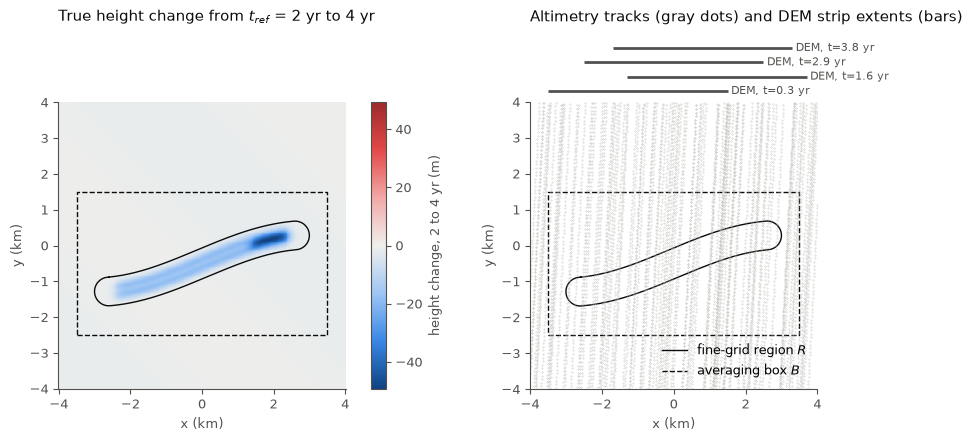

In [3]:
x_path = np.arange(-2600, 2601, 50.)
region = shapely.LineString(np.c_[x_path, rift_y(x_path)]).buffer(400)
print(f'region area: {region.area/1e6:.1f} km^2 of {(2*HW)**2/1e6:.0f} km^2')

# averaging box: the 1-km cells of the dz nodes with |x| <= 3 km, -2 km <= y <= 1 km
box_bounds = {'x': [-3500, 3500], 'y': [-2500, 1500]}
xm = np.arange(-HW, HW+1, 100.)
xmg, ymg = np.meshgrid(xm, xm)
box = pc.grid.data().from_dict({'x': xm, 'y': xm, 'z': ((np.abs(xmg) <= 3500) & (ymg >= -2500) & (ymg <= 1500)).astype(float)})

fig, ax = plt.subplots(1, 2, figsize=(10, 4.3), constrained_layout=True)
xx = np.arange(-HW, HW+1, 25.)
xg, yg = np.meshgrid(xx, xx)
change = z_true(xg, yg, 4.) - z_true(xg, yg, t_ref)
lim = np.abs(change).max()
h = ax[0].pcolormesh(xx/1000, xx/1000, change, cmap=div_cmap, norm=TwoSlopeNorm(0, -lim, lim), shading='nearest')
fig.colorbar(h, ax=ax[0], label='height change, 2 to 4 yr (m)')
ax[0].set_title('True height change from $t_{ref}$ = 2 yr to 4 yr', loc='left', color=ink, pad=58)
for this_ax in ax:
    this_ax.plot(*np.array(region.exterior.xy)/1000, color=ink, lw=1, label='fine-grid region $R$')
    this_ax.plot(np.array(box_bounds['x'])[[0, 1, 1, 0, 0]]/1000, np.array(box_bounds['y'])[[0, 0, 1, 1, 0]]/1000,
                 color=ink, lw=1, ls='--', label='averaging box $B$')
    this_ax.set_aspect('equal')
    this_ax.set_xlabel('x (km)'); this_ax.set_ylabel('y (km)')
alt = data[data.sensor == 0]
ax[1].plot(alt.x[::5]/1000, alt.y[::5]/1000, '.', color='#b8b7b1', ms=0.5)
# each DEM strip covers the full y range; show its x extent above the domain
for i, (t, xc) in enumerate(zip(DEM_times, DEM_xc)):
    y_bar = (HW + 300 + 400*i)/1000
    ax[1].plot([(xc-2500)/1000, (xc+2500)/1000], [y_bar, y_bar], color=ink2, lw=2, solid_capstyle='butt', clip_on=False)
    ax[1].text((xc+2600)/1000, y_bar, f'DEM, t={t} yr', va='center', fontsize=8, color=ink2, clip_on=False)
ax[1].set_xlim(-HW/1000, HW/1000); ax[1].set_ylim(-HW/1000, HW/1000)
ax[1].set_title('Altimetry tracks (gray dots) and DEM strip extents (bars)', loc='left', color=ink, pad=58)
ax[1].legend(loc='lower right', frameon=False);

## Fitting with and without the fine grids

We run the same fit twice.  The coarse fit uses a 200 m $z_0$ grid and a 1 km, quarterly $\delta z$ grid.  The second fit adds fine grids in $R$: 25 m nodes for $z_{0,f}$ and 50 m nodes for $\delta z_f$, with the same quarterly epochs.  The `spacing` entry takes either one number for both fine grids, or a dict like `smooth_fit`'s own `spacing` argument.

The fine-grid constraints are much weaker than the coarse ones: the $z_{0,f}$ curvature weight is 50 times the coarse one, and the $\delta z_f$ rate-curvature weight is 100 times the coarse one.  We also ask for the mean height change in the box $B$ through `avg_masks`, and for error estimates from the fine-grid fit.

In [4]:
E_RMS = {'d2z0_dx2': 0.02, 'dz0_dx': 0.02*2500, 'd3z_dx2dt': 0.003, 'd2z_dxdt': 0.003*2500, 'd2z_dt2': 5000}
fit_args = dict(data=data, ctr={'x': 0., 'y': 0., 't': 2.}, W={'x': 2*HW, 'y': 2*HW, 't': 4.},
                spacing={'z0': 200, 'dz': 1000, 'dt': 0.25}, E_RMS=E_RMS, reference_epoch=8,
                max_iterations=5, dzdt_lags=[1], avg_masks={'box': box}, solver='cholmod', VERBOSE=False)

fine_grid_args = {'region': region,
                  'spacing': {'z0': 25, 'dz': 50},
                  'E_RMS': {'d2z0_dx2': 1.0, 'd3z_dx2dt': 0.3, 'd2z_dt2': 100}}

S_coarse = smooth_fit(**fit_args)
S_fine = smooth_fit(**fit_args, fine_grid_args=fine_grid_args, compute_E=True)

for label, S in [('coarse', S_coarse), ('coarse + fine', S_fine)]:
    in_R = shapely.contains_xy(region, S['data'].x, S['data'].y)
    print(f"{label:14s}: {S['m']['all'].size:6d} model parameters; "
          f"{100*np.mean(~S['data'].three_sigma_edit[in_R]):4.1f}% of the data in R rejected as outliers")
for name in ['z0_fine', 'dz_fine']:
    grid = S_fine['grids'][name]
    print(f"{name}: {grid.delta[0]:.0f} m nodes, {grid.N_active} parameters")

coarse        :   3058 model parameters; 64.4% of the data in R rejected as outliers
coarse + fine :  41997 model parameters;  2.2% of the data in R rejected as outliers
z0_fine: 25 m nodes, 7787 parameters
dz_fine: 50 m nodes, 31152 parameters


The fine grids add about 39,000 parameters to the 3,000 of the coarse model; a model with the fine grids' resolution over the whole domain would have about 540,000.  The coarse fit cannot follow the rift, so its iterative editing rejects 64% of the data in $R$ as outliers.  The coarse+fine fit rejects 2%, mostly near the rift's propagating tip (see below).

## How well do the fits recover the surface?

We evaluate each model on a 25 m grid of points, $\mathbf{x}_i$, and compare it with the true surface:

$$
\epsilon_{RMS}(t) = \sqrt{\frac{1}{N}\sum_{i=1}^{N} \left[ z_m(\mathbf{x}_i, t) - z_{true}(\mathbf{x}_i, t) \right]^2 },
$$

separately for the points inside and outside $R$.  To evaluate the model at arbitrary points, we build the same interpolation operators that `smooth_fit` uses for the data; for the fine grids, `restrict_to_active` keeps only the nodes inside $R$.

coarse         inside R: 4.60 to 10.66 m, median 6.70 m
coarse         outside R: 0.31 to 0.81 m, median 0.46 m
coarse + fine  inside R: 1.86 to 6.16 m, median 2.64 m
coarse + fine  outside R: 0.08 to 0.17 m, median 0.08 m


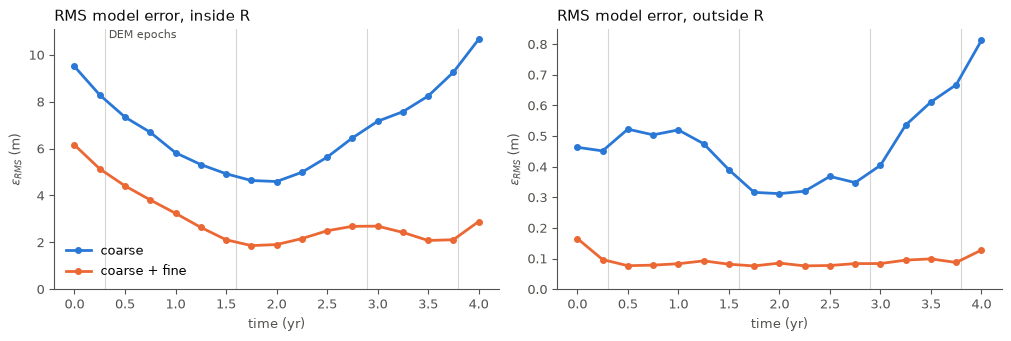

In [5]:
def model_at(S, x, y, t):
    # evaluate the full model (coarse + fine) at points (x, y, t)
    grids, m0 = S['grids'], S['m']['all']
    G = lin_op(grids['z0']).interp_mtx([y, x])
    G.add(lin_op(grids['dz']).interp_mtx([y, x, t]))
    for name, pts in [('z0_fine', [y, x]), ('dz_fine', [y, x, t])]:
        if name in grids:
            G.add(lin_op(grids[name]).interp_mtx(pts, bounds_error=False).restrict_to_active(drop_rows=False))
    return G.toCSR(row_N=x.size, col_N=m0.size).dot(m0)

xe, ye = [jj.ravel() for jj in np.meshgrid(np.arange(-HW+12.5, HW, 25.), np.arange(-HW+12.5, HW, 25.))]
in_region = shapely.contains_xy(region, xe, ye)
t_eval = np.arange(0, 4.01, 0.25)
rms_err = {}
for label, S in [('coarse', S_coarse), ('coarse + fine', S_fine)]:
    rms_err[label] = {'inside R': [], 'outside R': []}
    for t in t_eval:
        err = model_at(S, xe, ye, np.zeros_like(xe)+t) - z_true(xe, ye, t)
        rms_err[label]['inside R'].append(np.sqrt(np.mean(err[in_region]**2)))
        rms_err[label]['outside R'].append(np.sqrt(np.mean(err[~in_region]**2)))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3), constrained_layout=True)
for this_ax, where in zip(ax, ['inside R', 'outside R']):
    for label, color in [('coarse', c_coarse), ('coarse + fine', c_fine)]:
        this_ax.plot(t_eval, rms_err[label][where], color=color, lw=2, marker='o', ms=4, label=label)
    for t in DEM_times:
        this_ax.axvline(t, color='#d6d5d0', lw=0.8, zorder=0)
    this_ax.set_title(f'RMS model error, {where}', loc='left', color=ink)
    this_ax.set_xlabel('time (yr)'); this_ax.set_ylabel('$\\epsilon_{RMS}$ (m)')
    this_ax.set_ylim(bottom=0)
ax[0].legend(frameon=False)
ax[0].text(DEM_times[0], ax[0].get_ylim()[1], ' DEM epochs', color=ink2, va='top', fontsize=8)
for label in rms_err:
    for where in ['inside R', 'outside R']:
        v = np.array(rms_err[label][where])
        print(f'{label:14s} {where}: {v.min():.2f} to {v.max():.2f} m, median {np.median(v):.2f} m')

Inside $R$, the fine grids reduce the RMS error from 4.6 to 10.7 m (median 6.7 m) to 1.9 to 6.2 m (median 2.6 m).  Outside $R$, the coarse+fine fit is also much better (0.08 to 0.17 m, compared with 0.3 to 0.8 m), because the coarse fields no longer distort themselves trying to fit the rift.

Most of the remaining error inside $R$ comes from the part of the rift's path that the tip reaches during the record.  Along the rest of the rift, the RMS error of the coarse+fine model is 0.6 to 1.7 m.  As the tip passes a point, the trough there deepens by tens of meters within a few months, but the constraints on $\delta z_f$ penalize changes in its rate (`d2z_dt2`), so the model spreads the deepening over the whole record.  For example, at x = 2.2 km, where the tip arrives at t = 3.6 yr, the model is 37 m above the true surface at t = 0 and descends steadily through the record, and at t = 4 yr its trough is 17 m deep, where the true trough is 45 m deep.  Ahead of the tip, the RMS error is 10 m at t = 0, and single points are off by up to 57 m.  The editing rejects 7% of the data within 500 m of the tip, compared with 0.7% along the rest of the trough; for example, it rejects 17 of the 36 points on the trough near x = 2.2 km in the DEM from t = 3.8 yr.

The shaded-relief maps below show the north-south slope of the true surface and of the two fits at t = 2.9 yr, on the same gray scale.  The red line marks the location of the profiles that follow.

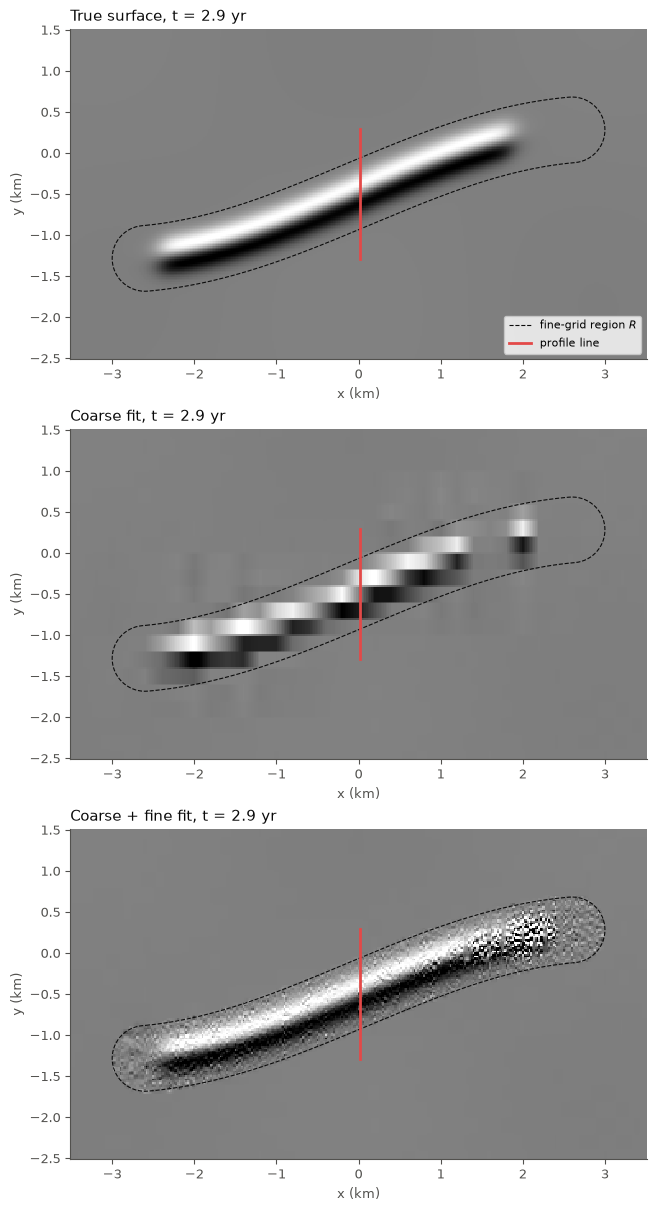

In [6]:
# location of the profiles shown below
x_prof = 12.5
ii = (xe == x_prof) & (np.abs(ye - rift_y(x_prof)) < 800)
order = np.argsort(ye[ii])
y_prof = ye[ii][order]
edges = [pt.y for pt in shapely.intersection(region.boundary, shapely.LineString([(x_prof, -HW), (x_prof, HW)])).geoms]

# shaded relief (north-south slope) of the true surface and of the two fits, within the box B
t_relief = 2.9
xr = np.arange(box_bounds['x'][0], box_bounds['x'][1]+1, 20.)
yr = np.arange(box_bounds['y'][0], box_bounds['y'][1]+1, 20.)
xrg, yrg = [jj.ravel() for jj in np.meshgrid(xr, yr)]
surfaces = {'True surface': z_true(xrg, yrg, t_relief),
            'Coarse fit': model_at(S_coarse, xrg, yrg, np.zeros_like(xrg)+t_relief),
            'Coarse + fine fit': model_at(S_fine, xrg, yrg, np.zeros_like(xrg)+t_relief)}
# the same gray scale for all three: the range of slopes of the true surface in R
slope_true = np.gradient(surfaces['True surface'].reshape(yr.size, xr.size), xr[1]-xr[0])[0]
clim = np.percentile(slope_true[shapely.contains_xy(region, xrg, yrg).reshape(yr.size, xr.size)], [1, 99])

fig, ax = plt.subplots(3, 1, figsize=(7.5, 12), constrained_layout=True)
for this_ax, (title, z) in zip(ax, surfaces.items()):
    pc.grid.data().from_dict({'x': xr, 'y': yr, 'z': z.reshape(yr.size, xr.size)})\
        .show(ax=this_ax, gradient=True, clim=clim, cmap='gray', xy_scale=1/1000)
    this_ax.plot(*np.array(region.exterior.xy)/1000, color=ink, lw=0.8, ls='--', label='fine-grid region $R$')
    this_ax.plot(np.zeros(2)+x_prof/1000, y_prof[[0, -1]]/1000, color='#e34948', lw=2, label='profile line')
    this_ax.set_title(f'{title}, t = {t_relief} yr', loc='left', color=ink)
    this_ax.set_xlabel('x (km)'); this_ax.set_ylabel('y (km)')
ax[0].legend(loc='lower right', fontsize=8);

The coarse fit renders the rift as a chain of blocks, the outlines of its 200 m $z_0$ cells and 1 km $\delta z$ cells.  The coarse+fine fit reproduces the walls of the trough, but its surface is grainy throughout $R$, at the scale of its 25 m nodes, and it is roughest near the tip (x ≈ 2 km) and at the west end of $R$, which only the first DEM covers.

The profiles across the rift show the same: the coarse model smears the trough over its nodes, while the fine grids follow it to within 3 m.

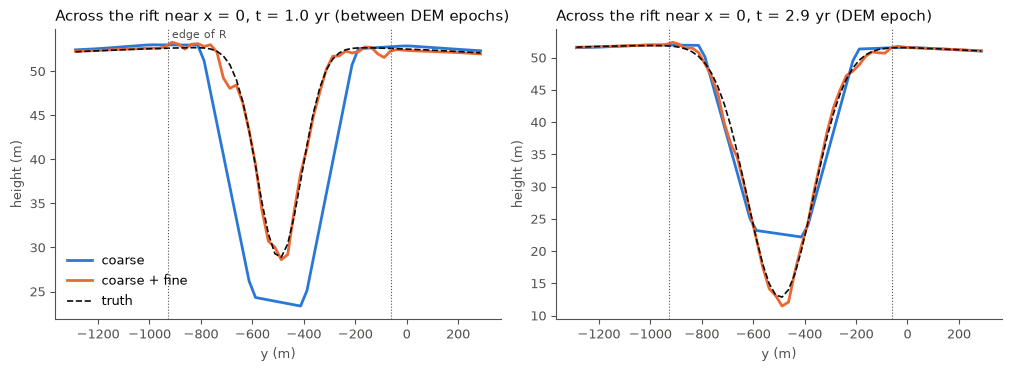

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for this_ax, t, when in zip(ax, [1.0, 2.9], ['between DEM epochs', 'DEM epoch']):
    for label, S, color in [('coarse', S_coarse, c_coarse), ('coarse + fine', S_fine, c_fine)]:
        z_m = model_at(S, xe[ii][order], y_prof, np.zeros_like(y_prof)+t)
        this_ax.plot(y_prof, z_m, color=color, lw=2, label=label)
    this_ax.plot(y_prof, z_true(xe[ii][order], y_prof, t), color=ink, lw=1.2, ls='--', label='truth')
    for y_edge in edges:
        this_ax.axvline(y_edge, color=ink2, lw=0.8, ls=':')
    this_ax.set_title(f'Across the rift near x = 0, t = {t} yr ({when})', loc='left', color=ink)
    this_ax.set_xlabel('y (m)'); this_ax.set_ylabel('height (m)')
ax[0].legend(frameon=False, loc='lower left')
ax[0].text(edges[0], ax[0].get_ylim()[1], ' edge of R', color=ink2, va='top', fontsize=8);

## The fine fields

`smooth_fit` returns the fine fields as `S['m']['z0_fine']` and `S['m']['dz_fine']`, on their own grids.  They are NaN outside $R$, and $\delta z_f$ is zero at the reference epoch.  The maps below show that the fine fields carry the rift, and that they become small towards the edge of $R$.  Near the east end of the rift's path, $z_{0,f}$ is noisy, with positive values where the model rises above the surface ahead of the tip, and $\delta z_f$ carries the rapid deepening that follows.  At the edge nodes they are not exactly zero: the model ramps them to zero over one fine-grid cell outside $R$, so the full model stays continuous.

`S['m']` also contains the coarse+fine totals on the fine grids, `z0_total_fine` and `dz_total_fine`, and their rates, `dzdt_total_fine_lag1`.  These are the fields to use for the full model near the rifts.  `S['m']['z0']` and `S['m']['dz']` are the coarse fields only.

fine-grid outputs: ['dz_fine', 'dz_total_fine', 'dzdt_total_fine_lag1', 'z0_fine', 'z0_total_fine']


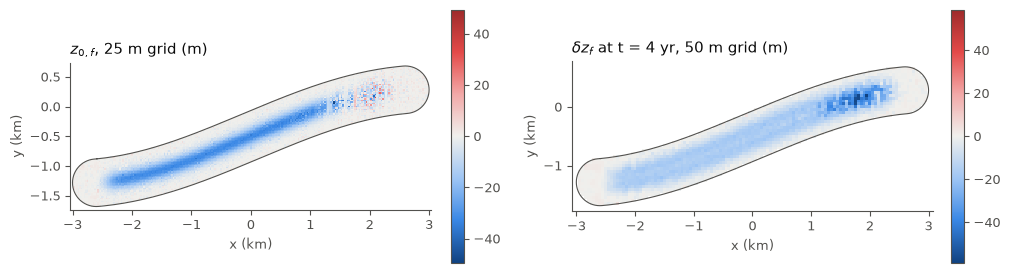

In [8]:
m = S_fine['m']
fig, ax = plt.subplots(1, 2, figsize=(10, 2.9), constrained_layout=True)
delta = {name: S_fine['grids'][name].delta[0] for name in ['z0_fine', 'dz_fine']}
for this_ax, field, vals, title in [
        (ax[0], m['z0_fine'], m['z0_fine'].z0_fine, f"$z_{{0,f}}$, {delta['z0_fine']:.0f} m grid (m)"),
        (ax[1], m['dz_fine'], m['dz_fine'].dz_fine[:, :, -1], f"$\\delta z_f$ at t = 4 yr, {delta['dz_fine']:.0f} m grid (m)")]:
    lim = np.nanmax(np.abs(vals))
    h = this_ax.pcolormesh(field.x/1000, field.y/1000, vals, cmap=div_cmap, norm=TwoSlopeNorm(0, -lim, lim), shading='nearest')
    this_ax.plot(*np.array(region.exterior.xy)/1000, color=ink2, lw=0.8)
    this_ax.set_aspect('equal'); this_ax.set_title(title, loc='left', color=ink)
    this_ax.set_xlabel('x (km)'); this_ax.set_ylabel('y (km)')
    fig.colorbar(h, ax=this_ax, shrink=0.9)
print('fine-grid outputs:', sorted(key for key in m if 'fine' in key))

## Regional averages include the fine fields

The coarse averaging outputs of `smooth_fit` (`avg_dz_*`, `avg_dzdt_*`, `dzdt_lag*`, and the `avg_masks` averages) include the fine fields, unless `fine_grid_args['add_to_coarse_averages']` is False.  For the box $B$, the reported mean height change is

$$
\overline{\delta z}_B(t) = \frac{1}{A_B}\int_B \left[ \delta z(x, y, t) + \delta z_f(x, y, t) \right] dA ,
$$

where $A_B$ is the area of $B$.  `smooth_fit` adds the fine field by spreading it onto the coarse nodes with the transpose of bilinear interpolation, which preserves its area integral.  A negative $\overline{\delta z}_B$ means the box lost volume since $t_{ref}$.

The figure compares the box averages from both fits with the true mean change in $B$.  The gray line is the coarse part of the coarse+fine fit alone: the area-weighted mean of `S['m']['dz']` over the box nodes, which is what the average would be without the fine field.

at t=4 yr: truth -2.85 m, coarse fit -2.22 m, coarse + fine fit -2.69 ± 0.05 m, coarse part alone -1.03 m


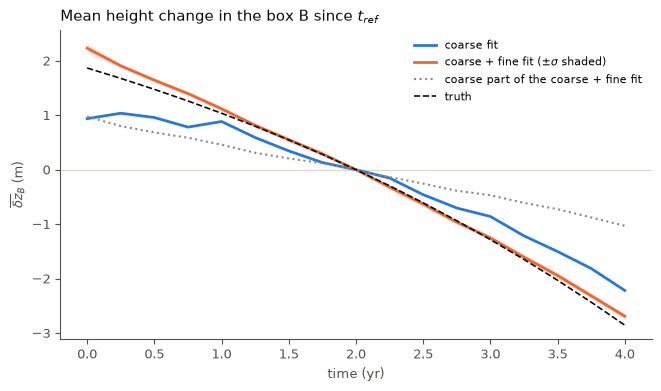

In [9]:
grid_dz = S_fine['grids']['dz']
t_dz = grid_dz.ctrs[2]
in_box = (xe >= box_bounds['x'][0]) & (xe <= box_bounds['x'][1]) & (ye >= box_bounds['y'][0]) & (ye <= box_bounds['y'][1])
truth = [np.mean(z_true(xe[in_box], ye[in_box], t) - z_true(xe[in_box], ye[in_box], t_ref)) for t in t_dz]

# coarse part only: the same box weights applied to the coarse dz nodes
w = box.interp(grid_dz.ctrs[1], grid_dz.ctrs[0], gridded=True)*grid_dz.cell_area
coarse_part = [np.sum(w*S_fine['m']['dz'].dz[:, :, k])/np.sum(w) for k in range(t_dz.size)]

avg_fine = S_fine['m']['box_avg_dz'].box_avg_dz.ravel()
sigma_fine = S_fine['E']['sigma_box_avg_dz'].sigma_box_avg_dz.ravel()
fig, ax = plt.subplots(figsize=(6.5, 3.8), constrained_layout=True)
ax.fill_between(t_dz, avg_fine-sigma_fine, avg_fine+sigma_fine, color=c_fine, alpha=0.2, lw=0)
ax.plot(t_dz, S_coarse['m']['box_avg_dz'].box_avg_dz.ravel(), color=c_coarse, lw=2, label='coarse fit')
ax.plot(t_dz, avg_fine, color=c_fine, lw=2, label='coarse + fine fit ($\\pm\\sigma$ shaded)')
ax.plot(t_dz, coarse_part, color='#8a8984', lw=1.5, ls=':', label='coarse part of the coarse + fine fit')
ax.plot(t_dz, truth, color=ink, lw=1.2, ls='--', label='truth')
ax.axhline(0, color='#d6d5d0', lw=0.8, zorder=0)
ax.set_xlabel('time (yr)'); ax.set_ylabel('$\\overline{\\delta z}_B$ (m)')
ax.set_title('Mean height change in the box B since $t_{ref}$', loc='left', color=ink)
ax.legend(frameon=False, fontsize=8)
print(f'at t=4 yr: truth {truth[-1]:.2f} m, coarse fit {S_coarse["m"]["box_avg_dz"].box_avg_dz.ravel()[-1]:.2f} m, '
      f'coarse + fine fit {avg_fine[-1]:.2f} ± {sigma_fine[-1]:.2f} m, coarse part alone {coarse_part[-1]:.2f} m')

From t = 1.25 to 3.25 yr, the coarse+fine average is within 0.04 m of the true mean change, within its error estimate.  At the ends of the record, it departs from the truth by 0.36 m at t = 0 and by 0.16 m at t = 4 yr, three to five times its error estimate, because of the errors ahead of and near the rift's tip.  The error estimate assumes that the data errors are random and that the surface follows the statistics implied by the constraint weights; the abrupt deepening at the tip violates the second assumption, and the estimate uses only the data that survive the editing.  The coarse fit recovers only half of the true change at t = 0 and underestimates it by 0.63 m at t = 4 yr, because it neither resolves the deepening trough nor keeps the rift data.  The coarse part of the coarse+fine fit misses 1.8 m at t = 4 yr: that is the volume change of the rift itself, which the fine field carries.

## Error estimates

With `compute_E=True`, `S['E']` contains errors for each output (`sigma_z0_fine`, `sigma_dz_fine`, `sigma_z0_total_fine`, ...).  The coarse and fine fields trade off against each other inside $R$, so their errors are correlated, and the error of a component can be larger than the error of the total.  Use the errors of the totals for the full model.

In [10]:
E = S_fine['E']
for key in ['sigma_z0_fine', 'sigma_z0_total_fine', 'sigma_dz_fine', 'sigma_dz_total_fine']:
    vals = getattr(E[key], key)
    print(f'{key:22s}: median {np.nanmedian(vals[vals > 0]):.2f} m')

sigma_z0_fine         : median 1.63 m
sigma_z0_total_fine   : median 1.33 m
sigma_dz_fine         : median 0.90 m
sigma_dz_total_fine   : median 0.92 m


## Error estimates at reduced resolution

Error propagation is the most expensive part of a fit with fine grids.  As `altimetryFit` does for the coarse grids, we can calculate the errors in a separate run with coarser fine grids, and interpolate them onto the fit's fine grids.  `fine_grid_args_for_errors` multiplies the fine-grid spacings by `fine_grid_args['error_res_scale']`, which is 4 for $z_{0,f}$ and 2 for $\delta z_f$ by default (100 m nodes for both here), and `fine_errors_to_grid` interpolates the errors back onto the fit's grids.  The error run uses the data from the fit, with the fit's editing (`three_sigma_edit`) and extra errors (`sigma_extra`), and does no iterations (`max_iterations=0`).  In `fit_altimetry.py`, the `error_res_scale` entry of the `--fine_grid_file` json file controls this, and a value of 1 calculates the errors at the fit's resolution.

In [11]:
from LSsurf.fine_grid_functions import fine_grid_args_for_errors, fine_errors_to_grid

fine_grid_args_E = fine_grid_args_for_errors(fine_grid_args)
print('fine-grid spacing for the error run:', {key: val for key, val in fine_grid_args_E['spacing'].items() if val is not None})
S_E = smooth_fit(**(fit_args | {'data': S_fine['data'], 'max_iterations': 0}),
                 fine_grid_args=fine_grid_args_E, compute_E=True)
for label, S in [('full resolution', S_fine), ('reduced resolution', S_E)]:
    n_fine = S['grids']['z0_fine'].N_active + S['grids']['dz_fine'].N_active
    print(f"{label:18s}: {n_fine:5d} fine-grid parameters, error calculation "
          f"{S['timing']['decompose_qz'] + S['timing']['propagate_errors']:.1f} s")

# the reduced-resolution errors, on the fit's fine grids
E_reduced = {}
for key in ['sigma_z0_total_fine', 'sigma_dz_total_fine']:
    E_full = S_fine['E'][key]
    full = getattr(E_full, key)
    coords = {'x': E_full.x, 'y': E_full.y} | ({'time': E_full.time} if full.ndim == 3 else {})
    E_reduced[key] = pc.grid.data().from_dict(coords | {
        key: fine_errors_to_grid(S_E['E'][key], E_full.x, E_full.y, field=key, valid=np.isfinite(full))})
    reduced = getattr(E_reduced[key], key)
    ok = np.isfinite(full) & (full > 0)
    print(f'{key:20s}: median full {np.median(full[ok]):.2f} m, reduced {np.median(reduced[ok]):.2f} m, '
          f'ratio reduced/full: median {np.median(reduced[ok]/full[ok]):.2f}, '
          f'10th-90th percentile {np.percentile(reduced[ok]/full[ok], 10):.2f}-{np.percentile(reduced[ok]/full[ok], 90):.2f}')
key = 'sigma_box_avg_dz'
print(f"{key:20s}: full {np.nanmedian(getattr(S_fine['E'][key], key)):.3f} m, "
      f"reduced {np.nanmedian(getattr(S_E['E'][key], key)):.3f} m (median over epochs)")

fine-grid spacing for the error run: {'z0': 100, 'dz': 100}


full resolution   : 38939 fine-grid parameters, error calculation 70.2 s
reduced resolution:  8211 fine-grid parameters, error calculation 7.7 s
sigma_z0_total_fine : median full 1.33 m, reduced 0.30 m, ratio reduced/full: median 0.23, 10th-90th percentile 0.10-0.52
sigma_dz_total_fine : median full 0.92 m, reduced 0.36 m, ratio reduced/full: median 0.42, 10th-90th percentile 0.28-0.58
sigma_box_avg_dz    : full 0.042 m, reduced 0.042 m (median over epochs)


The figure shows both error estimates along the profile line across the rift, for $z_0 + z_{0,f}$ and for $\delta z + \delta z_f$ at two epochs.  The gray band marks the trough, $|d| < w$, and the dotted lines mark the edges of $R$.

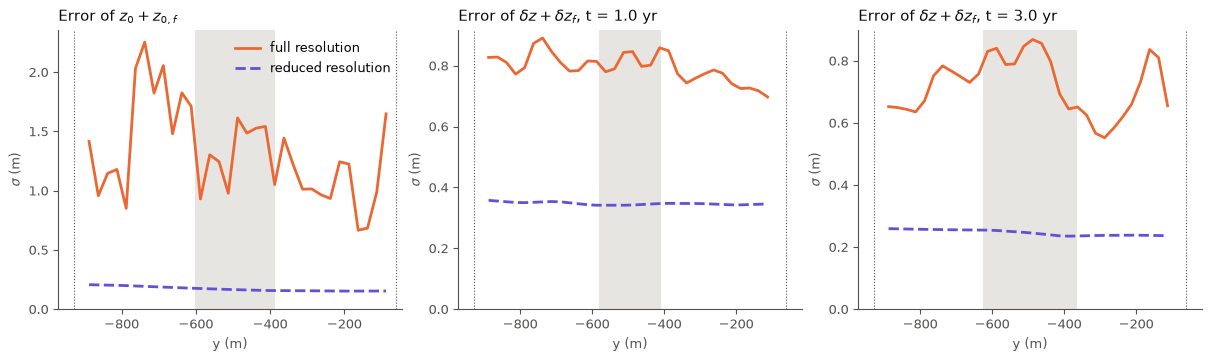

In [12]:
c_full, c_reduced = c_fine, '#6250d6'
panels = [('sigma_z0_total_fine', None, '$z_0 + z_{0,f}$'),
          ('sigma_dz_total_fine', 1.0, '$\\delta z + \\delta z_f$, t = 1.0 yr'),
          ('sigma_dz_total_fine', 3.0, '$\\delta z + \\delta z_f$, t = 3.0 yr')]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
for this_ax, (key, t, title) in zip(ax, panels):
    for label, E, color, ls in [('full resolution', S_fine['E'][key], c_full, '-'),
                                ('reduced resolution', E_reduced[key], c_reduced, '--')]:
        vals = getattr(E, key)
        if t is not None:
            vals = vals[:, :, np.argmin(np.abs(E.time - t))]
        sigma = pc.grid.data().from_dict({'x': E.x, 'y': E.y, 'z': vals}).interp(np.zeros_like(y_prof)+x_prof, y_prof)
        this_ax.plot(y_prof, sigma, color=color, lw=2, ls=ls, label=label)
    # the trough, |d| < w, along the north-south profile line
    w = (60 + 20*(t_ref if t is None else t))*np.sqrt(1 + (800*2*np.pi/12000*np.cos(2*np.pi*x_prof/12000))**2)
    this_ax.axvspan(rift_y(x_prof)-w, rift_y(x_prof)+w, color='#e6e5e1', lw=0, zorder=0)
    for y_edge in edges:
        this_ax.axvline(y_edge, color=ink2, lw=0.8, ls=':')
    this_ax.set_ylim(bottom=0)
    this_ax.set_title(f'Error of {title}', loc='left', color=ink)
    this_ax.set_xlabel('y (m)'); this_ax.set_ylabel('$\\sigma$ (m)')
ax[0].legend(frameon=False, loc='upper right');

The reduced-resolution error calculation is about ten times faster here (the timings are printed above), and the saving grows with the number of fine-grid parameters.  Its error for the box average is the same as at full resolution (0.042 m), but its node errors are much smaller.  Over $R$, the median ratio of reduced- to full-resolution errors is 0.23 for $z_0 + z_{0,f}$ and 0.42 for $\delta z + \delta z_f$ (10th to 90th percentiles 0.10 to 0.52 and 0.28 to 0.58).  Each node of a coarser grid represents a larger area and averages more data, so its error is smaller: the cells of a 4 times coarser $z_{0,f}$ grid have 16 times the area.  Along the profile, the full-resolution errors also vary more: the error of $z_0 + z_{0,f}$ varies between 0.7 and 2.3 m from node to node and is largest south of the trough, while the reduced-resolution errors are nearly constant.  The reduced-resolution errors are therefore suitable for regional averages, but they understate the errors at individual nodes; set `error_res_scale` to 1 when those matter.

The profiles stop short of the edges of $R$ because the interpolation needs fine-grid nodes inside $R$ on both sides of each point.

## Reference: `fine_grid_args`

| Entry | Meaning |
|---|---|
| `region` | shapely geometry, or a `pc.grid.data` mask that is nonzero inside the region (a time-varying mask is combined over time) |
| `region_file` | vector file (geojson, shp, gpkg; reprojected to the fit's projection if it has a CRS) or raster mask (tif, h5), used if `region` is not given |
| `region_field`, `region_group`, `region_threshold` | field and group to read from a raster file, and the mask value above which nodes are in the region (default 0.5) |
| `spacing` | one number for both fine grids, or `{'z0': ..., 'dz': ..., 'dt': ...}` (`dt` defaults to the time spacing of the $\delta z$ grid) |
| `buffer` | distance by which the region is expanded (default 0) |
| `E_RMS` | constraint weights for the fine fields (see below; at least one for each grid) |
| `add_to_coarse_averages` | include the fine fields in the coarse averaging outputs (default True) |
| `halo` | also center the constraint equations on this many nodes outside the region, which strengthens the pull towards zero at the edge (default 0) |

The `E_RMS` entries have the same meaning as in `smooth_fit`'s `E_RMS`, with units for x and y in m and t in yr:

| Grid | Entry | Constrains | Units |
|---|---|---|---|
| $z_{0,f}$ | `d2z0_dx2` | curvature | m$^{-1}$ |
| $z_{0,f}$ | `dz0_dx` | gradient | dimensionless |
| $z_{0,f}$ | `z0` | magnitude | m |
| $\delta z_f$ | `d3z_dx2dt` | curvature of the rate | m$^{-1}$ yr$^{-1}$ |
| $\delta z_f$ | `d2z_dxdt` | gradient of the rate | yr$^{-1}$ |
| $\delta z_f$ | `d2z_dt2` | curvature in time | m yr$^{-2}$ |
| $\delta z_f$ | `dz` | magnitude | m |

In `fit_altimetry.py` (altimetryFit), `--fine_grid_file` points to a json file with these entries, for example:

```json
{"region_file": "rift_region.geojson",
 "spacing": {"z0": 25, "dz": 50, "dt": 0.25},
 "E_RMS": {"d2z0_dx2": 1.0, "d3z_dx2dt": 0.3, "d2z_dt2": 100}}
```

A relative `region_file` path is read relative to the json file.  The region must be in the coordinates of the fit; with `--lagrangian`, these are the advected coordinates at the Lagrangian epoch.